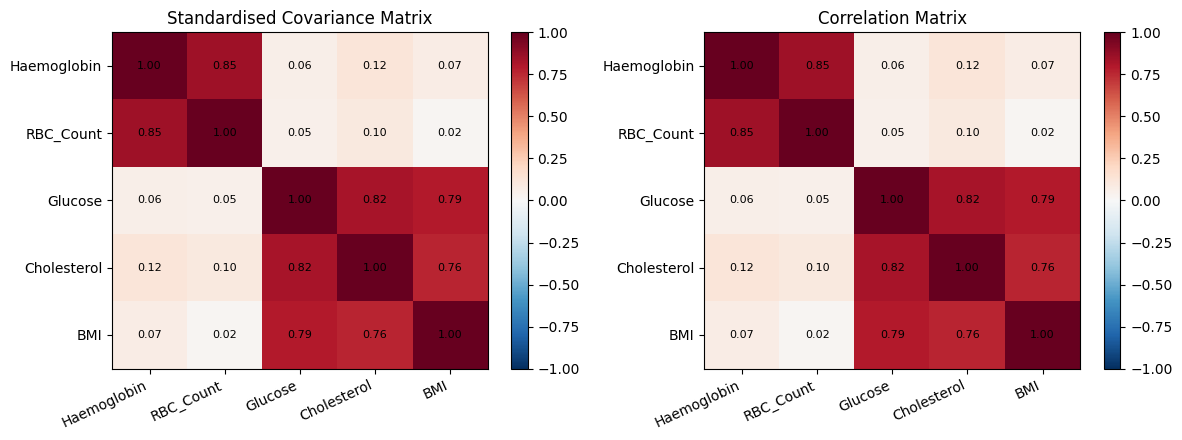

PC1: eigenvalue = 2.6221, variance explained = 52.44%
PC2: eigenvalue = 1.8154, variance explained = 36.31%
PC3: eigenvalue = 0.2448, variance explained = 4.90%
PC4: eigenvalue = 0.1765, variance explained = 3.53%
PC5: eigenvalue = 0.1413, variance explained = 2.83%


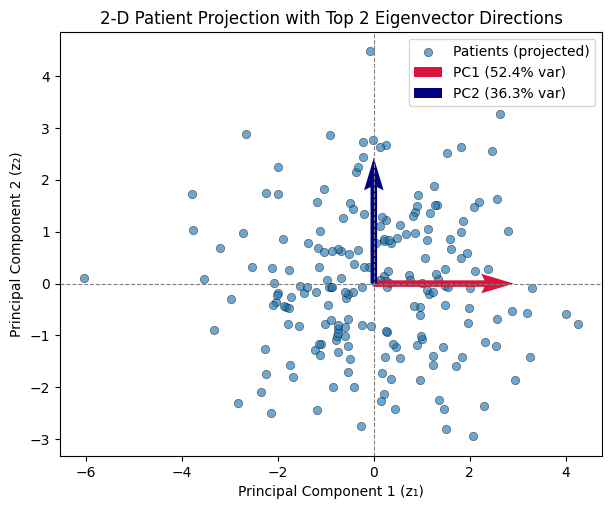

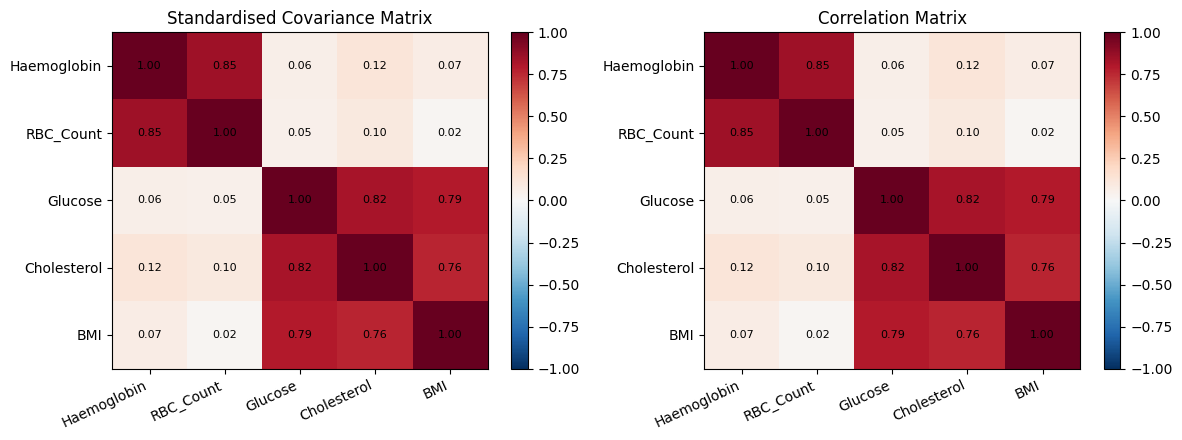

PC1: eigenvalue = 2.6221, variance explained = 52.44%
PC2: eigenvalue = 1.8154, variance explained = 36.31%
PC3: eigenvalue = 0.2448, variance explained = 4.90%
PC4: eigenvalue = 0.1765, variance explained = 3.53%
PC5: eigenvalue = 0.1413, variance explained = 2.83%


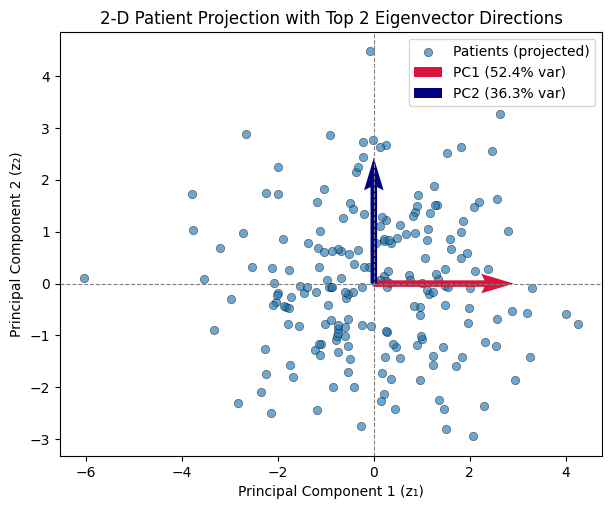

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
n = 200

# 1. Create / load 200 patient records with correlated blood & metabolic features
latent_vitality = np.random.normal(0, 1, n)
latent_metabolic = np.random.normal(0, 1, n)

df = pd.DataFrame({
    "Haemoglobin": np.clip(14.2 + 1.3 * latent_vitality + np.random.normal(0, 0.5, n), 9.0, 18.5),
    "RBC_Count": np.clip(4.8 + 0.45 * latent_vitality + np.random.normal(0, 0.2, n), 3.5, 6.5),
    "Glucose": np.clip(98 + 18 * latent_metabolic + np.random.normal(0, 8, n), 65, 180),
    "Cholesterol": np.clip(190 + 28 * latent_metabolic + 0.3 * 12 * latent_vitality + np.random.normal(0, 14, n), 120, 290),
    "BMI": np.clip(24.5 + 3.2 * latent_metabolic + np.random.normal(0, 1.8, n), 16.0, 38.0),
})

features = df.columns.tolist()

# Standardise each feature (mean = 0, std = 1)
X = df.values.astype(float)
X_std = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)

# 2. Covariance and correlation matrices
cov_matrix = np.cov(X_std, rowvar=False)
corr_matrix = np.corrcoef(X_std, rowvar=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, mat, title in zip(
    axes,
    [cov_matrix, corr_matrix],
    ["Standardised Covariance Matrix", "Correlation Matrix"]
):
    im = ax.imshow(mat, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(features)))
    ax.set_xticklabels(features, rotation=25, ha="right")
    ax.set_yticks(range(len(features)))
    ax.set_yticklabels(features)
    ax.set_title(title)
    for r in range(len(features)):
        for c in range(len(features)):
            ax.text(c, r, f"{mat[r, c]:.2f}", ha="center", va="center", color="black", fontsize=8)
    plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.savefig("exp02_cov_corr_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Eigenvalues and eigenvectors sorted descending
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
idx_sort = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx_sort]
eigenvectors = eigenvectors[:, idx_sort]

# 4 & 5. Percentage of variance captured by each eigenvalue
explained_var_ratio = eigenvalues / np.sum(eigenvalues) * 100
for k, (val, pct) in enumerate(zip(eigenvalues, explained_var_ratio), start=1):
    print(f"PC{k}: eigenvalue = {val:.4f}, variance explained = {pct:.2f}%")

# Project standardised data onto top 2 eigenvectors (PC1 and PC2)
W2 = eigenvectors[:, :2]          # (5, 2)
Z2 = X_std @ W2                   # (200, 2)

# Plot 2-D projected data with top 2 eigenvector directions drawn as arrows
plt.figure(figsize=(7, 5.5))
plt.scatter(Z2[:, 0], Z2[:, 1], alpha=0.65, edgecolors="k", linewidths=0.4, label="Patients (projected)")

# Arrows in projected PC1-PC2 space scaled by sqrt(eigenvalue)
arrow_scales = np.sqrt(eigenvalues[:2]) * 1.8
plt.quiver(
    0, 0, arrow_scales[0], 0,
    angles="xy", scale_units="xy", scale=1, color="crimson", width=0.012,
    label=f"PC1 ({explained_var_ratio[0]:.1f}% var)"
)
plt.quiver(
    0, 0, 0, arrow_scales[1],
    angles="xy", scale_units="xy", scale=1, color="navy", width=0.012,
    label=f"PC2 ({explained_var_ratio[1]:.1f}% var)"
)

plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)
plt.xlabel("Principal Component 1 (z₁)")
plt.ylabel("Principal Component 2 (z₂)")
plt.title("2-D Patient Projection with Top 2 Eigenvector Directions")
plt.legend()
plt.savefig("exp02_pca_2d_arrows.png", dpi=150, bbox_inches="tight")
plt.show()